# How `Qdrant/BM25` compute the sparse vector

In [4]:
from collections import Counter
from fastembed.sparse import SparseTextEmbedding


model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

text = """A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS."""

vec = next(model.embed([text]))
print(f"Text: {text} \nLength of text: {len(text)}\n")
print("=== Sparse vector ===")
print("indices:", vec.indices)
print("values:", vec.values)
print("non-zero dimensions:", len(vec.indices))


# Use FastEmbed's real internal BM25 preprocessing
tokens = bm25.tokenizer.tokenize(text.lower())

# Remove stopwords
tokens_no_stopwords = [
    token for token in tokens
    if token not in bm25.stopwords
]

# Stem correctly: pass a list, not one string
if not bm25.disable_stemmer:
    final_terms = bm25._stem(tokens_no_stopwords)
else:
    final_terms = tokens_no_stopwords

# Compute ids from final terms
term_counts = Counter(final_terms)

index_to_value = {
    int(i): float(v)
    for i, v in zip(vec.indices, vec.values)
}

print("\n=== Included terms ===")
print(f"{'term':<40} {'count':<8} {'index':<15} {'value'}")
print("-" * 60)

for term, count in term_counts.items():
    idx = int(bm25.compute_token_id(term))
    value = index_to_value.get(idx, 0.0)

    print(f"{term:<40} {count:<8} {idx:<15} {value}")


print("\n=== Dropped stopwords ===")
dropped = [
    token for token in tokens
    if token in bm25.stopwords
]
print(dropped)

Text: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS. 
Length of text: 92

=== Sparse vector ===
indices: [1471019746 1298296063  938217065  390168769  801873620 1796268431
 1714506967 1035623941 1270418937]
values: [1.65209739 1.65209739 1.65209739 1.65209739 1.65209739 1.65209739
 1.65209739 1.65209739 1.65209739]
non-zero dimensions: 9

=== Included terms ===
term                                     count    index           value
------------------------------------------------------------
retrospect                               1        1471019746      1.6520973892637139
analysi                                  1        1298296063      1.6520973892637139
conduct                                  1        938217065       1.6520973892637139
332                                      1        390168769       1.6520973892637139
adult                                    1        801873620       1.6520973892637139
patient                         

# Dense Vector

=== Dense vector ===
Model: nomic-embed-text:latest
Vector shape: (768,)
Number of dimensions: 768
Text: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.
Length of text: 92
First 20 values:
[ 0.12341617  0.47731912 -3.80318975 -0.86197102  0.29201481 -0.09571008
  0.35264501  0.29629505  0.32974315  0.07025451  0.20927286  0.80875099
  1.83334589 -0.70772731 -0.11114966 -1.90498936 -0.26641327 -0.76917195
 -1.31194413  1.27386403]

=== Dense vector stats ===
Min: -3.803189754486084
Max: 1.961925745010376
Mean: 0.005980435071402705
Non-zero values: 768
Zero values: 0


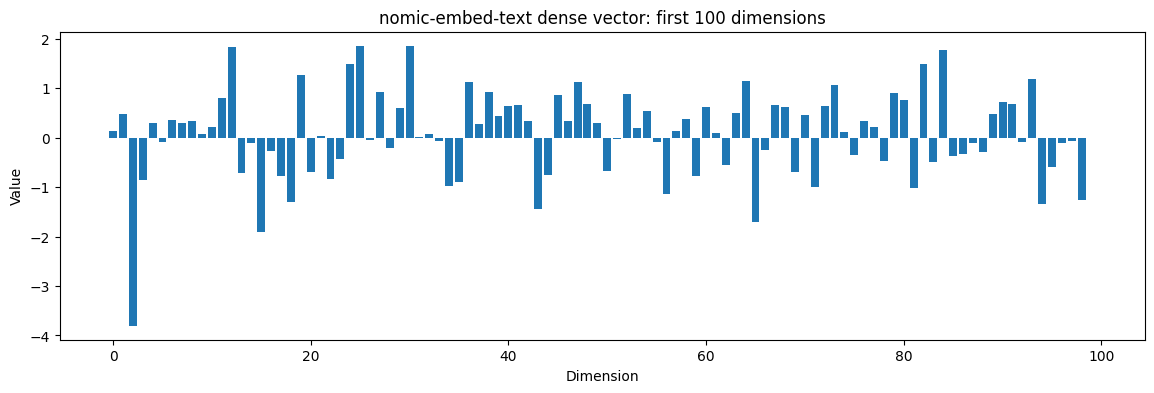

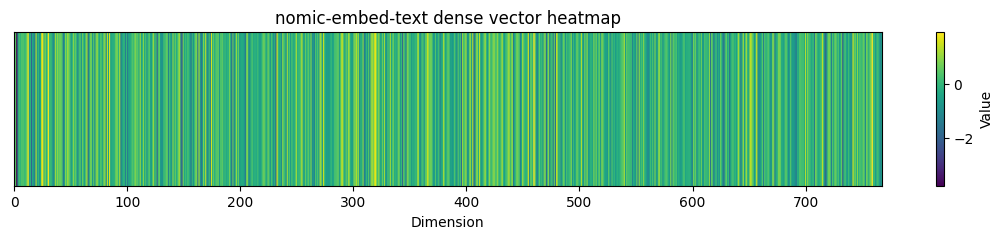

In [2]:
import requests
import numpy as np
import matplotlib.pyplot as plt

text = """A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS."""

response = requests.post(
    "http://localhost:11434/api/embeddings",
    json={
        "model": "nomic-embed-text:latest",
        "prompt": text,
    },
)

response.raise_for_status()

vec = np.array(response.json()["embedding"])

print("=== Dense vector ===")
print("Model: nomic-embed-text:latest")
print("Vector shape:", vec.shape)
print("Number of dimensions:", len(vec))
print("Text:", text)
print("Length of text:", len(text))
print("First 20 values:")
print(vec[:20])

print("\n=== Dense vector stats ===")
print("Min:", vec.min())
print("Max:", vec.max())
print("Mean:", vec.mean())
print("Non-zero values:", np.count_nonzero(vec))
print("Zero values:", len(vec) - np.count_nonzero(vec))

# Plot first 100 dimensions
n = 100

plt.figure(figsize=(14, 4))
plt.bar(range(n), vec[:n])
plt.title(f"nomic-embed-text dense vector: first {n} dimensions")
plt.xlabel("Dimension")
plt.ylabel("Value")
plt.show()

# Heatmap-like visualization
plt.figure(figsize=(14, 2))
plt.imshow(vec.reshape(1, -1), aspect="auto")
plt.title("nomic-embed-text dense vector heatmap")
plt.xlabel("Dimension")
plt.yticks([])
plt.colorbar(label="Value")
plt.show()